# Bootstrap, Permutation, and Resampling Methods
---

## Experiment: enumerate all 27 nonparametric bootstrap samples exactly.

In [2]:
import itertools
import numpy as np

x = np.array([2., 4., 6.])
boot_means = np.array([np.mean(sample)
                       for sample in itertools.product(x, repeat=len(x))])

values, counts = np.unique(np.round(boot_means, 10), return_counts=True)
print("Bootstrap mean : count")
for mean, count in zip(values, counts):
    print(f"{mean:8.4f} : {count:2d}")
print("Conditional mean:", boot_means.mean())
print("Conditional standard error:", boot_means.std(ddof=0))

Bootstrap mean : count
  2.0000 :  1
  2.6667 :  3
  3.3333 :  6
  4.0000 :  7
  4.6667 :  6
  5.3333 :  3
  6.0000 :  1
Conditional mean: 4.0
Conditional standard error: 0.9428090415820635


## Experiment: visualize the bootstrap distribution of a sample mean.

Observed sample mean: 17.875
Bootstrap standard error: 2.059


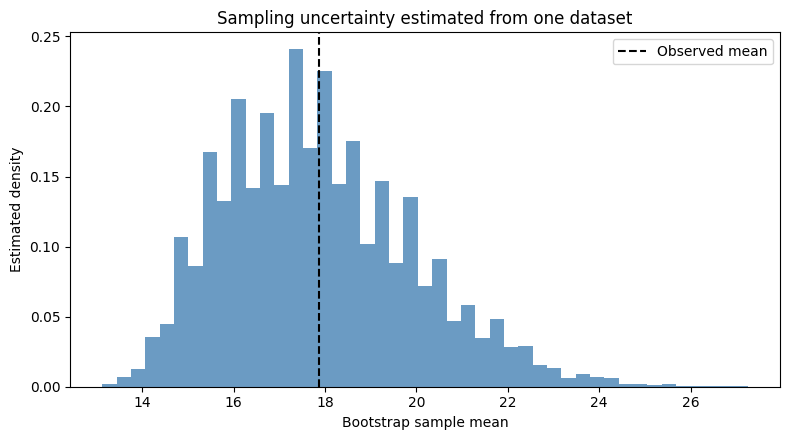

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([12, 14, 15, 15, 17, 18, 20, 32], dtype=float)
rng = np.random.default_rng(2026)
B = 10_000
bootstrap_means = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
print(f"Observed sample mean: {x.mean():.3f}")
print(f"Bootstrap standard error: {bootstrap_means.std(ddof=1):.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(bootstrap_means, bins=45, density=True, color="steelblue", alpha=0.8)
ax.axvline(x.mean(), color="black", linestyle="--", label="Observed mean")
ax.set(xlabel="Bootstrap sample mean", ylabel="Estimated density",
       title="Sampling uncertainty estimated from one dataset")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/resampling_bootstrap_means.png", dpi=160)
plt.show()

## Experiment: calculate percentile and basic bootstrap intervals without a library wrapper.

In [4]:
import numpy as np

x = np.array([12, 14, 15, 15, 17, 18, 20, 32], dtype=float)
rng = np.random.default_rng(2026)
B = 10_000
est = x.mean()
replicates = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
low, high = np.quantile(replicates, [0.025, 0.975])

print(f"Point estimate: {est:.3f} seconds")
print(f"Percentile 95% CI: ({low:.3f}, {high:.3f})")
print(f"Basic 95% CI:      ({2*est-high:.3f}, {2*est-low:.3f})")

Point estimate: 17.875 seconds
Percentile 95% CI: (14.625, 22.375)
Basic 95% CI:      (13.375, 21.125)


## Experiment: compare percentile, basic, and BCa confidence intervals using SciPy.

In [5]:
import numpy as np
from scipy import stats

x = np.array([12, 14, 15, 15, 17, 18, 20, 32], dtype=float)

for method in ("percentile", "basic", "BCa"):
    result = stats.bootstrap(
        (x,), np.mean, confidence_level=0.95,
        n_resamples=10_000, method=method,
        rng=np.random.default_rng(2026)
    )
    ci = result.confidence_interval
    print(f"{method:>10s}: [{ci.low:.3f}, {ci.high:.3f}], "
          f"bootstrap SE = {result.standard_error:.3f}")



percentile: [14.625, 22.375], bootstrap SE = 2.059
     basic: [13.375, 21.125], bootstrap SE = 2.059
       BCa: [15.125, 24.250], bootstrap SE = 2.059


##  Experiment: compare mean and median uncertainty in the presence of an extreme value.

In [6]:
import numpy as np

original = np.array([12, 14, 15, 15, 17, 18, 20, 32], dtype=float)
contaminated = original.copy()
contaminated[-1] = 80  # illustrative data edit, not a real observation

for label, x in (("Original", original), ("With extreme value", contaminated)):
    rng = np.random.default_rng(2026)
    idx = rng.integers(0, len(x), size=(10_000, len(x)))
    samples = x[idx]
    mean_bs = samples.mean(axis=1)
    median_bs = np.median(samples, axis=1)
    print(label)
    print("  mean =", x.mean(), "CI =", np.quantile(mean_bs, [0.025, 0.975]))
    print("  median =", np.median(x), "CI =", np.quantile(median_bs, [0.025, 0.975]))

Original
  mean = 17.875 CI = [14.625 22.375]
  median = 16.0 CI = [14. 20.]
With extreme value
  mean = 23.875 CI = [14.625 40.375]
  median = 16.0 CI = [14. 20.]


## Experiment: bootstrap independent-group and paired mean differences correctly.

In [7]:
import numpy as np

rng = np.random.default_rng(2026)
B = 10_000

# Two independent groups: resample within each group separately.
a = np.array([10, 11, 12, 13], dtype=float)
b = np.array([4, 5, 6, 7], dtype=float)
a_boot = rng.choice(a, (B, len(a)), replace=True).mean(axis=1)
b_boot = rng.choice(b, (B, len(b)), replace=True).mean(axis=1)
independent_effect = a_boot - b_boot
print("Independent mean difference:", a.mean() - b.mean())
print("Independent percentile CI:", np.quantile(independent_effect, [.025, .975]))

# Matched before/after measurements: resample the differences/rows together.
before = np.array([40, 42, 41, 43, 44, 39], dtype=float)
after = np.array([42, 45, 45, 48, 51, 47], dtype=float)
differences = after - before
idx = rng.integers(0, len(differences), size=(B, len(differences)))
paired_effect = differences[idx].mean(axis=1)
print("Paired mean difference:", differences.mean())
print("Paired percentile CI:", np.quantile(paired_effect, [.025, .975]))

Independent mean difference: 6.0
Independent percentile CI: [4.5 7.5]
Paired mean difference: 4.833333333333333
Paired percentile CI: [3.16666667 6.5       ]


## Experiment: enumerate all 70 label allocations and plot the exact null distribution.

Observed difference: 6.0
Extreme allocations: 2 / 70
Exact two-sided p-value: 0.028571


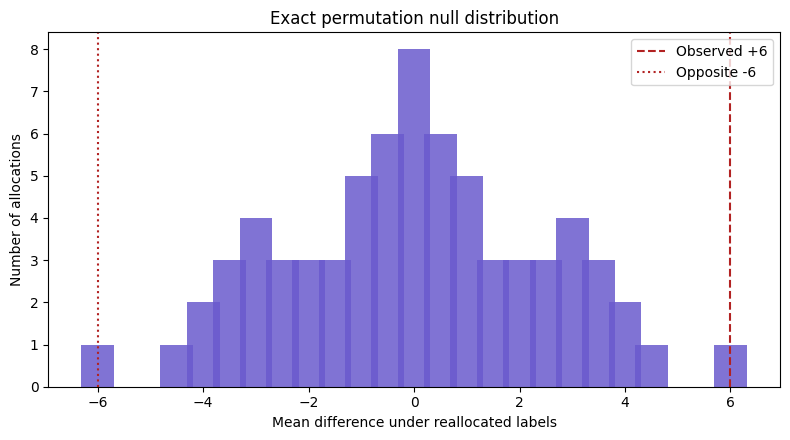

In [8]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

A = np.array([10., 11., 12., 13.])
B = np.array([4., 5., 6., 7.])
pooled = np.concatenate([A, B])
observed = A.mean() - B.mean()

null = []
for group_a_idx in itertools.combinations(range(len(pooled)), len(A)):
    mask = np.zeros(len(pooled), dtype=bool)
    mask[list(group_a_idx)] = True
    null.append(pooled[mask].mean() - pooled[~mask].mean())
null = np.asarray(null)
extreme = np.count_nonzero(np.abs(null) >= abs(observed) - 1e-12)
p_value = extreme / len(null)
print(f"Observed difference: {observed:.1f}")
print(f"Extreme allocations: {extreme} / {len(null)}")
print(f"Exact two-sided p-value: {p_value:.6f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
values, counts = np.unique(null, return_counts=True)
ax.bar(values, counts, width=0.62, color="slateblue", alpha=0.85)
ax.axvline(observed, color="firebrick", linestyle="--", label="Observed +6")
ax.axvline(-observed, color="firebrick", linestyle=":", label="Opposite -6")
ax.set(xlabel="Mean difference under reallocated labels",
       ylabel="Number of allocations", title="Exact permutation null distribution")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/resampling_permutation_null.png", dpi=160)
plt.show()

## Experiment: compare a randomized permutation test with a reproducible SciPy calculation.

In [9]:
import numpy as np
from scipy import stats

# Larger samples: there are C(20,10)=184,756 possible group allocations.
a = np.array([12, 14, 15, 16, 17, 19, 20, 23, 25, 28], dtype=float)
b = np.array([9, 13, 14, 15, 16, 17, 19, 20, 21, 23], dtype=float)

def diff_means(x, y):
    return np.mean(x) - np.mean(y)

for B in (999, 9999):
    test = stats.permutation_test(
        (a, b), diff_means,
        permutation_type="independent", alternative="two-sided",
        n_resamples=B, vectorized=False,
        rng=np.random.default_rng(2026)
    )
    print(f"{B:5d} random reallocations: T={test.statistic:.3f}, "
          f"approximate p={test.pvalue:.5f}")

# For the tiny teaching example, request exact enumeration instead.
exact = stats.permutation_test(
    ([10, 11, 12, 13], [4, 5, 6, 7]), diff_means,
    permutation_type="independent", n_resamples=np.inf,
    alternative="two-sided", vectorized=False
)
print(f"Exact p-value for Worked example 3: {exact.pvalue:.8f}")

  999 random reallocations: T=2.200, approximate p=0.33000
 9999 random reallocations: T=2.200, approximate p=0.32720
Exact p-value for Worked example 3: 0.02857143


## Experiment: enumerate an exact paired sign-flip test and verify it in SciPy.

In [10]:
import itertools
import numpy as np
from scipy import stats

d = np.array([2., 3., 4., 5., 7., 8.])
observed = d.mean()
null = np.array([np.mean(d * signs)
                 for signs in itertools.product((-1, 1), repeat=len(d))])
p_exact = np.mean(np.abs(null) >= abs(observed) - 1e-12)
print(f"Observed paired mean change: {observed:.4f}")
print(f"Exact sign-flip p-value: {p_exact:.5f}")

def average_change(x):
    return np.mean(x)

check = stats.permutation_test(
    (d,), average_change, permutation_type="samples",
    alternative="two-sided", n_resamples=np.inf,
    vectorized=False
)
print(f"SciPy paired permutation p-value: {check.pvalue:.5f}")

Observed paired mean change: 4.8333
Exact sign-flip p-value: 0.03125
SciPy paired permutation p-value: 0.03125


##  Experiment: contrast parametric and nonparametric bootstrap standard errors.

In [11]:
import numpy as np

x = np.array([0.3, 0.5, 0.6, 1.0, 1.2, 2.4, 3.5])
n = len(x)
mu_hat = x.mean()
rng = np.random.default_rng(2026)
B = 10_000

# Parametric model: Exponential(scale=mu_hat).
param_samples = rng.exponential(scale=mu_hat, size=(B, n))
param_means = param_samples.mean(axis=1)

# Nonparametric: sample from the observed empirical distribution.
nonparam_samples = rng.choice(x, size=(B, n), replace=True)
nonparam_means = nonparam_samples.mean(axis=1)

print(f"Estimated exponential mean: {mu_hat:.4f}")
print(f"Model-based theoretical SE: {mu_hat/np.sqrt(n):.4f}")
print(f"Parametric bootstrap SE: {param_means.std(ddof=1):.4f}")
print(f"Nonparametric bootstrap SE: {nonparam_means.std(ddof=1):.4f}")

Estimated exponential mean: 1.3571
Model-based theoretical SE: 0.5130
Parametric bootstrap SE: 0.5129
Nonparametric bootstrap SE: 0.4106


##  Experiment: estimate the coverage of percentile bootstrap intervals by simulation.

normal     : coverage=0.952, mean CI width=0.953
exponential: coverage=0.880, mean CI width=0.909


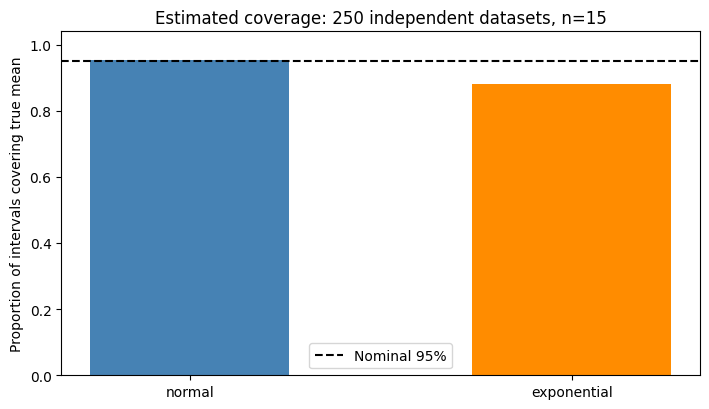

In [12]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
n, studies, B = 15, 250, 700
results = {}

for population in ("normal", "exponential"):
    covered = 0
    lengths = []
    true_mean = 1.0
    for _ in range(studies):
        if population == "normal":
            x = rng.normal(loc=true_mean, scale=1.0, size=n)
        else:
            x = rng.exponential(scale=true_mean, size=n)
        boot = rng.choice(x, size=(B, n), replace=True).mean(axis=1)
        lo, hi = np.quantile(boot, [0.025, 0.975])
        covered += (lo <= true_mean <= hi)
        lengths.append(hi - lo)
    results[population] = (covered / studies, np.mean(lengths))
    print(f"{population:11s}: coverage={covered/studies:.3f}, "
          f"mean CI width={np.mean(lengths):.3f}")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
labels = list(results)
coverage = [results[name][0] for name in labels]
ax.bar(labels, coverage, width=0.52, color=["steelblue", "darkorange"])
ax.axhline(0.95, color="black", linestyle="--", label="Nominal 95%")
ax.set(ylim=(0, 1.04), ylabel="Proportion of intervals covering true mean",
       title=f"Estimated coverage: {studies} independent datasets, n={n}")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/resampling_coverage.png", dpi=160)
plt.show()

## Experiment: compare an invalid i.i.d. bootstrap with a moving-block bootstrap for serial data.

Naive i.i.d. bootstrap SE: 0.1212
Moving-block bootstrap SE (L=12): 0.3083


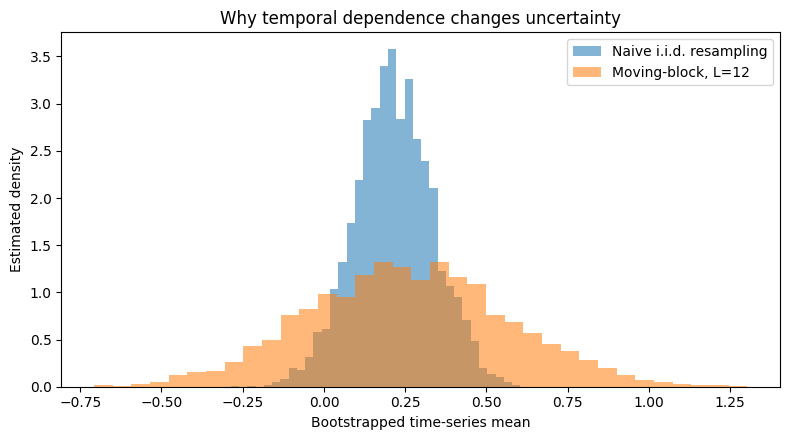

In [13]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
phi, n, B, L = 0.80, 240, 3500, 12
innovations = rng.normal(size=n + 150)
series = np.zeros(n + 150)
for t in range(1, len(series)):
    series[t] = phi * series[t - 1] + innovations[t]
x = series[150:]  # discard initial transient

# Incorrect for serially dependent observations: resample single hours.
iid_indices = rng.integers(0, n, size=(B, n))
iid_means = x[iid_indices].mean(axis=1)

# Sample contiguous moving blocks, preserving within-block dependence.
num_blocks = int(np.ceil(n / L))
starts = rng.integers(0, n - L + 1, size=(B, num_blocks))
offsets = np.arange(L)
block_indices = (starts[:, :, None] + offsets).reshape(B, -1)[:, :n]
block_means = x[block_indices].mean(axis=1)

print(f"Naive i.i.d. bootstrap SE: {iid_means.std(ddof=1):.4f}")
print(f"Moving-block bootstrap SE (L={L}): {block_means.std(ddof=1):.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(iid_means, bins=35, alpha=0.55, density=True, label="Naive i.i.d. resampling")
ax.hist(block_means, bins=35, alpha=0.55, density=True, label=f"Moving-block, L={L}")
ax.set(xlabel="Bootstrapped time-series mean", ylabel="Estimated density",
       title="Why temporal dependence changes uncertainty")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/resampling_block_dependence.png", dpi=160)
plt.show()